###**CASE STUDY - NETFLIX**

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Loading the dataset and Analysing

In [44]:
df = pd.read_csv('netflix_titles.csv')
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [45]:
len(df)

8807

In [46]:
df.shape

(8807, 12)

In [47]:
df.dtypes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [49]:
df.nunique()

,0
show_id,8807
type,2
title,8807
director,4528
cast,7692
country,748
date_added,1767
release_year,74
rating,17
duration,220


In [50]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [51]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [52]:
df.duplicated().value_counts()

,count
False,8807


Unnesting the data

In [53]:
df['cast'].value_counts().head()

,count
cast,
David Attenborough,19
"Vatsal Dubey, Julie Tejwani, Rupa Bhimani, Jigna Bhardwaj, Rajesh Kava, Mousam, Swapnil",14
Samuel West,10
Jeff Dunham,7
"David Spade, London Hughes, Fortune Feimster",6


In [54]:
actor_df = df[['title','cast']]
actor_df.head()

,title,cast
0,Dick Johnson Is Dead,NaN
1,Blood & Water,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban..."
2,Ganglands,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi..."
3,Jailbirds New Orleans,NaN
4,Kota Factory,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K..."


In [55]:
#converted the cast into a list so that it becomes iterable for us to use the explode function in the next step.
actor_df['actor'] = actor_df['cast'].apply(lambda x: str(x).split(', '))
actor_df.head(10)

<ipython-input-55-c0d615dc8923>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  actor_df['actor'] = actor_df['cast'].apply(lambda x: str(x).split(', '))


,title,cast,actor
0,Dick Johnson Is Dead,NaN,[nan]
1,Blood & Water,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...","[Ama Qamata, Khosi Ngema, Gail Mabalane, Thaba..."
2,Ganglands,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...","[Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nab..."
3,Jailbirds New Orleans,NaN,[nan]
4,Kota Factory,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...","[Mayur More, Jitendra Kumar, Ranjan Raj, Alam ..."
5,Midnight Mass,"Kate Siegel, Zach Gilford, Hamish Linklater, H...","[Kate Siegel, Zach Gilford, Hamish Linklater, ..."
6,My Little Pony: A New Generation,"Vanessa Hudgens, Kimiko Glenn, James Marsden, ...","[Vanessa Hudgens, Kimiko Glenn, James Marsden,..."
7,Sankofa,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","[Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra ..."
8,The Great British Baking Show,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...","[Mel Giedroyc, Sue Perkins, Mary Berry, Paul H..."
9,The Starling,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...","[Melissa McCarthy, Chris O'Dowd, Kevin Kline, ..."


In [56]:
actor_df = actor_df.explode('actor')
actor_df.head()

,title,cast,actor
0,Dick Johnson Is Dead,NaN,nan
1,Blood & Water,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",Ama Qamata
1,Blood & Water,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",Khosi Ngema
1,Blood & Water,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",Gail Mabalane
1,Blood & Water,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",Thabang Molaba


In [57]:
actor_df['actor'].value_counts()

,count
actor,
nan,825
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
...,...
Melanie Straub,1
Gabriela Maria Schmeide,1
Helena Zengel,1


In [58]:
actor_df = actor_df.drop('cast', axis=1)
actor_df.head()

,title,actor
0,Dick Johnson Is Dead,nan
1,Blood & Water,Ama Qamata
1,Blood & Water,Khosi Ngema
1,Blood & Water,Gail Mabalane
1,Blood & Water,Thabang Molaba


Now, unnesting the country column

In [59]:
df['country'].value_counts()

,count
country,
United States,2818
India,972
United Kingdom,419
Japan,245
South Korea,199
...,...
"Romania, Bulgaria, Hungary",1
"Uruguay, Guatemala",1
"France, Senegal, Belgium",1


In [61]:
#finding all the rows where country column has ','.
col_name = 'country'
df[df[col_name].apply(lambda x : ',' in str(x))].head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
12,s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic","September 23, 2021",2021,TV-MA,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...
29,s30,Movie,Paranoia,Robert Luketic,"Liam Hemsworth, Gary Oldman, Amber Heard, Harr...","United States, India, France","September 19, 2021",2013,PG-13,106 min,Thrillers,"Blackmailed by his company's CEO, a low-level ..."
38,s39,Movie,Birth of the Dragon,George Nolfi,"Billy Magnussen, Ron Yuan, Qu Jingjing, Terry ...","China, Canada, United States","September 16, 2021",2017,PG-13,96 min,"Action & Adventure, Dramas",A young Bruce Lee angers kung fu traditionalis...
46,s47,Movie,Safe House,Daniel Espinosa,"Denzel Washington, Ryan Reynolds, Vera Farmiga...","South Africa, United States, Japan","September 16, 2021",2012,R,115 min,Action & Adventure,Young CIA operative Matt Weston must get a dan...


In [62]:
country_df = df[['title','country']]
country_df['country_list'] = country_df['country'].apply(lambda x: str(x).split(', '))
country_df = country_df.explode('country_list')

country_df.head()

<ipython-input-62-cd3067307595>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  country_df['country_list'] = country_df['country'].apply(lambda x: str(x).split(', '))


,title,country,country_list
0,Dick Johnson Is Dead,United States,United States
1,Blood & Water,South Africa,South Africa
2,Ganglands,NaN,nan
3,Jailbirds New Orleans,NaN,nan
4,Kota Factory,India,India


In [63]:
country_df = country_df.drop('country', axis=1)
country_df.head()

,title,country_list
0,Dick Johnson Is Dead,United States
1,Blood & Water,South Africa
2,Ganglands,nan
3,Jailbirds New Orleans,nan
4,Kota Factory,India


In [65]:
#merging using title as anchor column.
merge_df1 = pd.merge(left = actor_df, right = country_df, on='title')
merge_df1.head()

,title,actor,country_list
0,Dick Johnson Is Dead,nan,United States
1,Blood & Water,Ama Qamata,South Africa
2,Blood & Water,Khosi Ngema,South Africa
3,Blood & Water,Gail Mabalane,South Africa
4,Blood & Water,Thabang Molaba,South Africa


In [66]:
#grouping list of country and actor using my anchor column title.
merge_df1.groupby(['actor',"country_list"])['title'].nunique().sort_values(ascending=False)

actor                country_list  
nan                  United States     406
                     nan               154
                     United Kingdom     96
Anupam Kher          India              40
nan                  India              39
                                      ... 
Juana Viale          United States       1
Boubker Ait El Caid  France              1
Botho Molohloane     South Africa        1
Juanita de Villiers  South Africa        1
Ṣọpẹ́ Dìrísù         United Kingdom      1
Name: title, Length: 54892, dtype: int64

Unnesting Director column

In [67]:
df['director'].value_counts()

,count
director,
Rajiv Chilaka,19
"Raúl Campos, Jan Suter",18
Marcus Raboy,16
Suhas Kadav,16
Jay Karas,14
...,...
"Raymie Muzquiz, Stu Livingston",1
Joe Menendez,1
Eric Bross,1


In [68]:
#finding all the rows where director column has ','.
col_name = 'director'
df[df[col_name].apply(lambda x : ',' in str(x))].shape

(614, 12)

In [69]:
director_df = df[['title','director']]
director_df['director_list'] = director_df['director'].apply(lambda x: str(x).split(', '))
director_df = director_df.explode('director_list')

director_df.head()

<ipython-input-69-6466fa5bedea>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  director_df['director_list'] = director_df['director'].apply(lambda x: str(x).split(', '))


,title,director,director_list
0,Dick Johnson Is Dead,Kirsten Johnson,Kirsten Johnson
1,Blood & Water,NaN,nan
2,Ganglands,Julien Leclercq,Julien Leclercq
3,Jailbirds New Orleans,NaN,nan
4,Kota Factory,NaN,nan


In [70]:
director_df = director_df.drop('director', axis=1)
director_df.head()

,title,director_list
0,Dick Johnson Is Dead,Kirsten Johnson
1,Blood & Water,nan
2,Ganglands,Julien Leclercq
3,Jailbirds New Orleans,nan
4,Kota Factory,nan


Unnesting the Genre column

In [71]:
genre_df = df[['title','listed_in']]
genre_df['genre'] = genre_df['listed_in'].apply(lambda x: str(x).split(', '))
genre_df = genre_df.explode('genre')

genre_df.head()

<ipython-input-71-7102c8562c44>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  genre_df['genre'] = genre_df['listed_in'].apply(lambda x: str(x).split(', '))


,title,listed_in,genre
0,Dick Johnson Is Dead,Documentaries,Documentaries
1,Blood & Water,"International TV Shows, TV Dramas, TV Mysteries",International TV Shows
1,Blood & Water,"International TV Shows, TV Dramas, TV Mysteries",TV Dramas
1,Blood & Water,"International TV Shows, TV Dramas, TV Mysteries",TV Mysteries
2,Ganglands,"Crime TV Shows, International TV Shows, TV Act...",Crime TV Shows


In [72]:
genre_df = genre_df.drop('listed_in', axis=1)
genre_df.head()

,title,genre
0,Dick Johnson Is Dead,Documentaries
1,Blood & Water,International TV Shows
1,Blood & Water,TV Dramas
1,Blood & Water,TV Mysteries
2,Ganglands,Crime TV Shows


In [74]:
#merging using title as anchor column.
merge_df2 = pd.merge(left = director_df, right = genre_df, on='title')
merge_df2.head()

,title,director_list,genre
0,Dick Johnson Is Dead,Kirsten Johnson,Documentaries
1,Blood & Water,nan,International TV Shows
2,Blood & Water,nan,TV Dramas
3,Blood & Water,nan,TV Mysteries
4,Ganglands,Julien Leclercq,Crime TV Shows


In [75]:
df_new = pd.merge(left = merge_df1, right = merge_df2, on='title')
df_new

,title,actor,country_list,director_list,genre
0,Dick Johnson Is Dead,nan,United States,Kirsten Johnson,Documentaries
1,Blood & Water,Ama Qamata,South Africa,nan,International TV Shows
2,Blood & Water,Ama Qamata,South Africa,nan,TV Dramas
3,Blood & Water,Ama Qamata,South Africa,nan,TV Mysteries
4,Blood & Water,Khosi Ngema,South Africa,nan,International TV Shows
...,...,...,...,...,...
201986,Zubaan,Anita Shabdish,India,Mozez Singh,International Movies
201987,Zubaan,Anita Shabdish,India,Mozez Singh,Music & Musicals
201988,Zubaan,Chittaranjan Tripathy,India,Mozez Singh,Dramas
201989,Zubaan,Chittaranjan Tripathy,India,Mozez Singh,International Movies


In [76]:
df_new.groupby(['actor',"country_list","director_list",'genre'])['title'].nunique().sort_values(ascending=False)

actor         country_list    director_list  genre                 
nan           United States   nan            Docuseries                84
                                             Reality TV                41
              nan             nan            Docuseries                31
              United Kingdom  nan            British TV Shows          29
              United States   nan            Crime TV Shows            28
                                                                       ..
He Jiang      China           Liu Jiang      Dramas                     1
                                             International Movies       1
He Meixuan    China           nan            International TV Shows     1
                                             Romantic TV Shows          1
Ṣọpẹ́ Dìrísù  United Kingdom  Remi Weekes    Independent Movies         1
Name: title, Length: 190255, dtype: int64

Merging unnested data with original data

In [77]:
df_final = pd.merge(left = df, right = df_new, on='title')
df_final = df_final.drop(columns=['cast', 'country', 'director', 'listed_in','description'], axis=1)
df_final.head()

,show_id,type,title,date_added,release_year,rating,duration,actor,country_list,director_list,genre
0,s1,Movie,Dick Johnson Is Dead,"September 25, 2021",2020,PG-13,90 min,nan,United States,Kirsten Johnson,Documentaries
1,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,nan,International TV Shows
2,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,nan,TV Dramas
3,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,nan,TV Mysteries
4,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Khosi Ngema,South Africa,nan,International TV Shows


In [78]:
df_final.shape

(201991, 11)

Dealing with missing data

In [79]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In the duration column, it was observed that the nulls had values which were written in corresponding rating column,i.e., you cant expect rating to be min. So the duration column nulls are replaced by corresponding values in rating column

In [80]:
df_final.loc[df_final['duration'].isna(),'duration'] = df_final.loc[df_final['duration'].isna(),'duration'].fillna(df_final['rating'])
df_final.loc[df_final['rating'].str.contains('min', na=False), 'rating'] = 'NR'
df_final.isna().sum()

,0
show_id,0
type,0
title,0
date_added,158
release_year,0
rating,67
duration,0
actor,0
country_list,0
director_list,0


In [81]:
df_final.loc[df_final['rating'].str.contains('min', na=False), 'rating'] = 'NR'
df_final['rating'].fillna('NR',inplace=True)
pd.set_option('display.max_rows', None)
df_final.isna().sum()

,0
show_id,0
type,0
title,0
date_added,158
release_year,0
rating,0
duration,0
actor,0
country_list,0
director_list,0


Date added column is imputed on the basis of release year, i.e., suppose there's a null for date added when release year was 2013. so the below code just checks the mode of date added for the release year=2013 and imputes in place of nulls the corresponding mode.

In [82]:
for i in df_final[df_final['date_added'].isnull()]['release_year'].unique():
  imp = df_final[df_final['release_year']==i]['date_added'].mode().values[0]
  df_final.loc[df_final['release_year']==i,'date_added']=df_final.loc[(df_final['release_year']==i,'date_added')].fillna(imp)

In [98]:
#replacing nan values of director and actor by Unknown Actor and Director
df_final['actor'].replace(['nan'],['Unknown Actor'],inplace=True)
df_final['director_list'].replace(['nan'],['Unknown Director'],inplace=True)
df_final['country_list'].replace(['nan'],[np.nan],inplace=True)
df_final.head()

,show_id,type,title,date_added,release_year,rating,duration,actor,country_list,director_list,genre,duration_copy
0,s1,Movie,Dick Johnson Is Dead,"September 25, 2021",2020,PG-13,90,Unknown Actor,United States,Kirsten Johnson,Documentaries,90
1,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,International TV Shows,2 Seasons
2,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Dramas,2 Seasons
3,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Mysteries,2 Seasons
4,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Khosi Ngema,South Africa,Unknown Director,International TV Shows,2 Seasons


In [112]:
#country column is imputed on the basis of director,i.e- suppose there's a null for country
#when we have a director whose other movies have a country given.So below piece of code just checks the mode of
#country for the director
# and imputes in place of nulls the corresponding mode

for i in df_final[df_final['country_list'].isnull()]['director_list'].unique(): # all the places where corresponding country is missing for a director
  if i in df_final[~df_final['country_list'].isnull()]['director_list'].unique():
    imp=df_final[df_final['director_list']==i]['country_list'].mode().values[0]
    df_final.loc[df_final['director_list']==i,'country_list']=df_final.loc[df_final['director_list']==i,'country_list'].fillna(imp)

In [113]:
df_final.isna().sum()

,0
show_id,0
type,0
title,0
date_added,0
release_year,0
rating,0
duration,0
actor,0
country_list,4276
director_list,0


Dealing with duration column by creating bins

In [100]:
df_final['duration'].value_counts()

,count
duration,
1 Season,35035
2 Seasons,9559
3 Seasons,5084
94,4343
106,4040
97,3624
95,3560
96,3484
93,3480


In [101]:
df_final['duration'] = df_final['duration'].str.replace('min','')
df_final.head()

,show_id,type,title,date_added,release_year,rating,duration,actor,country_list,director_list,genre,duration_copy
0,s1,Movie,Dick Johnson Is Dead,"September 25, 2021",2020,PG-13,90,Unknown Actor,United States,Kirsten Johnson,Documentaries,90
1,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,International TV Shows,2 Seasons
2,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Dramas,2 Seasons
3,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Mysteries,2 Seasons
4,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Khosi Ngema,South Africa,Unknown Director,International TV Shows,2 Seasons


In [102]:
df_final['duration'].unique()

array(['90 ', '2 Seasons', '1 Season', '91 ', '125 ', '9 Seasons', '104 ',
       '127 ', '4 Seasons', '67 ', '94 ', '5 Seasons', '161 ', '61 ',
       '166 ', '147 ', '103 ', '97 ', '106 ', '111 ', '3 Seasons', '110 ',
       '105 ', '96 ', '124 ', '116 ', '98 ', '23 ', '115 ', '122 ', '99 ',
       '88 ', '100 ', '6 Seasons', '102 ', '93 ', '95 ', '85 ', '83 ',
       '113 ', '13 ', '182 ', '48 ', '145 ', '87 ', '92 ', '80 ', '117 ',
       '128 ', '119 ', '143 ', '114 ', '118 ', '108 ', '63 ', '121 ',
       '142 ', '154 ', '120 ', '82 ', '109 ', '101 ', '86 ', '229 ',
       '76 ', '89 ', '156 ', '112 ', '107 ', '129 ', '135 ', '136 ',
       '165 ', '150 ', '133 ', '70 ', '84 ', '140 ', '78 ', '7 Seasons',
       '64 ', '59 ', '139 ', '69 ', '148 ', '189 ', '141 ', '130 ',
       '138 ', '81 ', '132 ', '10 Seasons', '123 ', '65 ', '68 ', '66 ',
       '62 ', '74 ', '131 ', '39 ', '46 ', '38 ', '8 Seasons',
       '17 Seasons', '126 ', '155 ', '159 ', '137 ', '12 ', '273 ', '36 ',


In [103]:
df_final['duration_copy']=df_final['duration'].copy()
df_final1 = df_final.copy()

In [104]:
df_final1.loc[df_final1['duration_copy'].str.contains('Season'), 'duration_copy'] = 0
df_final1['duration_copy'] = df_final1['duration_copy'].astype(int)
df_final1.head()

,show_id,type,title,date_added,release_year,rating,duration,actor,country_list,director_list,genre,duration_copy
0,s1,Movie,Dick Johnson Is Dead,"September 25, 2021",2020,PG-13,90,Unknown Actor,United States,Kirsten Johnson,Documentaries,90
1,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,International TV Shows,0
2,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Dramas,0
3,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Mysteries,0
4,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Khosi Ngema,South Africa,Unknown Director,International TV Shows,0


In [105]:
df_final1['duration_copy'].describe()

,duration_copy
count,201991.000000
mean,77.152789
std,52.269154
min,0.000000
25%,0.000000
50%,95.000000
75%,112.000000
max,312.000000


<ipython-input-106-2e7a3ba5cf46>:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_final1['duration_copy'], hist=True, kde=True,


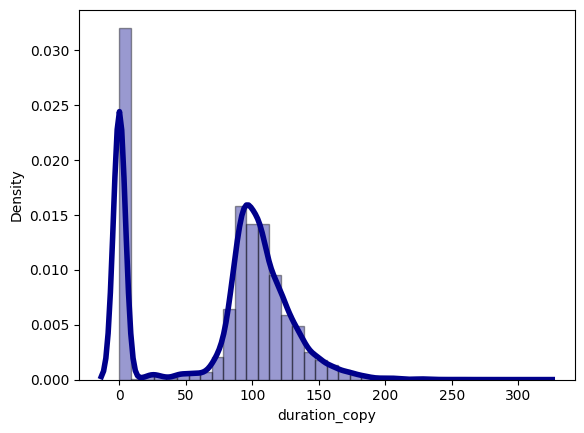

In [106]:
sns.distplot(df_final1['duration_copy'], hist=True, kde=True,
             bins=int(36), color = 'darkblue',
             hist_kws={'edgecolor':'black'},
             kde_kws={'linewidth':4})
plt.show()

In [107]:
bins1 = [-1,1,50,80,100,120,150,200,315]
labels1 = ['<1','1-50','51-80','81-100','101-120','121-150','151-200','201-315']
df_final1['duration_copy'] = pd.cut(df_final1['duration_copy'], bins=bins1, labels=labels1)
df_final1.head()

,show_id,type,title,date_added,release_year,rating,duration,actor,country_list,director_list,genre,duration_copy
0,s1,Movie,Dick Johnson Is Dead,"September 25, 2021",2020,PG-13,90,Unknown Actor,United States,Kirsten Johnson,Documentaries,81-100
1,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,International TV Shows,<1
2,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Dramas,<1
3,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Mysteries,<1
4,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Khosi Ngema,South Africa,Unknown Director,International TV Shows,<1


In [108]:
df_final1['duration_copy'].value_counts()

,count
duration_copy,
<1,56148
81-100,52937
101-120,48724
121-150,26691
51-80,7700
151-200,6737
1-50,2530
201-315,524


In [109]:
df_final1.loc[~df_final1['duration'].str.contains('Season'), 'duration'] = df_final1.loc[~df_final1['duration'].str.contains('Season'), 'duration_copy']
df_final1.drop('duration_copy', axis=1, inplace=True)
df_final1.head()

,show_id,type,title,date_added,release_year,rating,duration,actor,country_list,director_list,genre
0,s1,Movie,Dick Johnson Is Dead,"September 25, 2021",2020,PG-13,81-100,Unknown Actor,United States,Kirsten Johnson,Documentaries
1,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,International TV Shows
2,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Dramas
3,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Mysteries
4,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Khosi Ngema,South Africa,Unknown Director,International TV Shows


In [110]:
df_final1['duration'].value_counts()

,count
duration,
81-100,52937
101-120,48724
1 Season,35035
121-150,26691
2 Seasons,9559
51-80,7700
151-200,6737
3 Seasons,5084
1-50,2530


Dealing with date formatting

In [ ]:
df_final1['date_added'] = pd.to_datetime(df_final1['date_added'])
df_final1['month_added'] = df_final1['date_added'].dt.month
df_final1['month_name_added'] = df_final1['date_added'].dt.month_name()
df_final1['year_added'] = df_final1['date_added'].dt.year
df_final1.head()

**Insights based on the above data**

In [114]:
df_final1.head()

,show_id,type,title,date_added,release_year,rating,duration,actor,country_list,director_list,genre
0,s1,Movie,Dick Johnson Is Dead,"September 25, 2021",2020,PG-13,81-100,Unknown Actor,United States,Kirsten Johnson,Documentaries
1,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,International TV Shows
2,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Dramas
3,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Ama Qamata,South Africa,Unknown Director,TV Mysteries
4,s2,TV Show,Blood & Water,"September 24, 2021",2021,TV-MA,2 Seasons,Khosi Ngema,South Africa,Unknown Director,International TV Shows


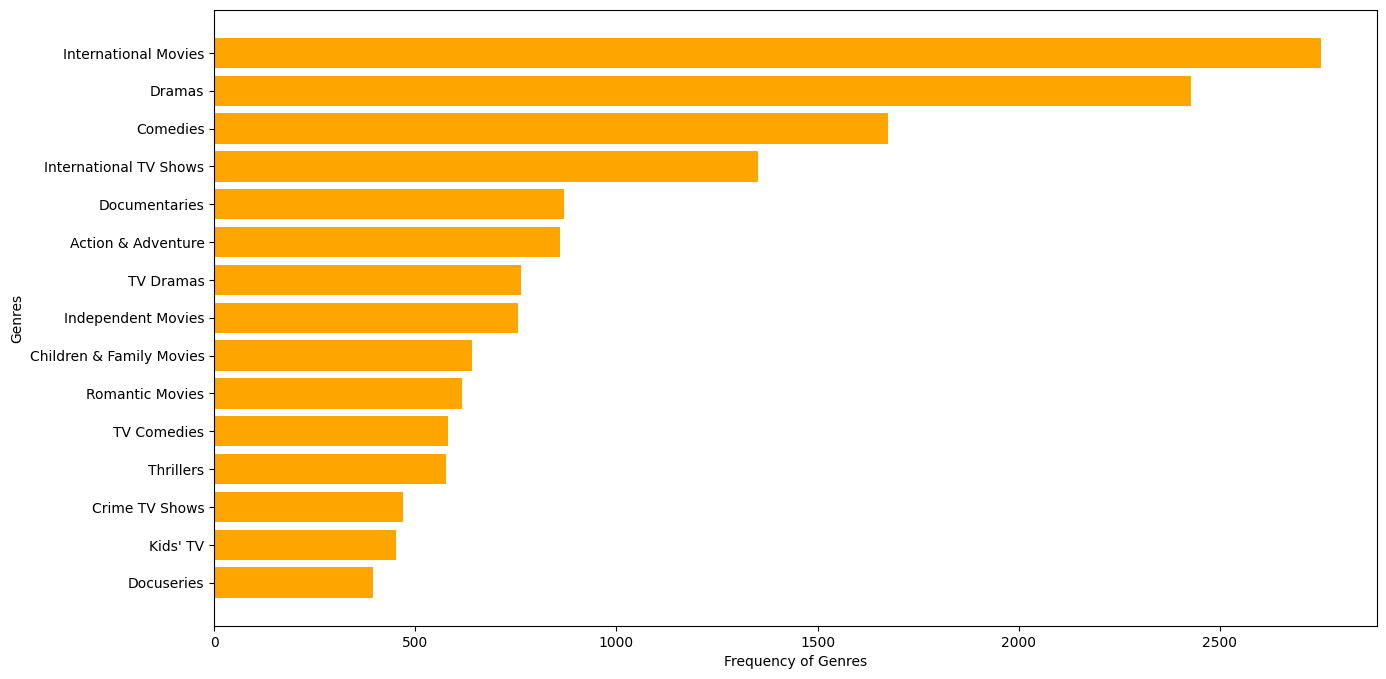

In [115]:
df_genre=df_final1.groupby(['genre']).agg({"title":"nunique"}).reset_index().sort_values(by=['title'],ascending=False)[:15]
plt.figure(figsize=(15,8))
plt.barh(df_genre[::-1]['genre'], df_genre[::-1]['title'],color=['orange'])
plt.xlabel('Frequency of Genres')
plt.ylabel('Genres')
plt.show()

International Movies, Dramas and Comedies are the most popular .

In [116]:
#number of distinct titles on the basis of type
df_final1.groupby(['type']).agg({"title":"nunique"})

,title
type,
Movie,6131
TV Show,2676


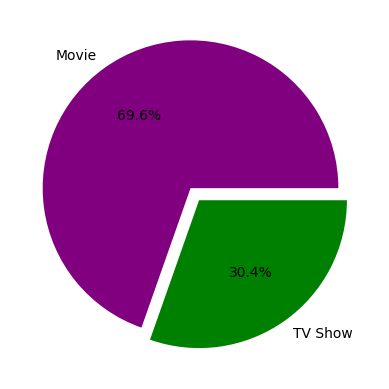

In [117]:
df_type=df_final1.groupby(['type']).agg({"title":"nunique"}).reset_index()
plt.pie(df_type['title'],explode=(0.05,0.05), labels=df_type['type'],colors=['purple','green'],autopct='%.1f%%')
plt.show()

We have 70:30 ratio of Movies and TV Shows in our data

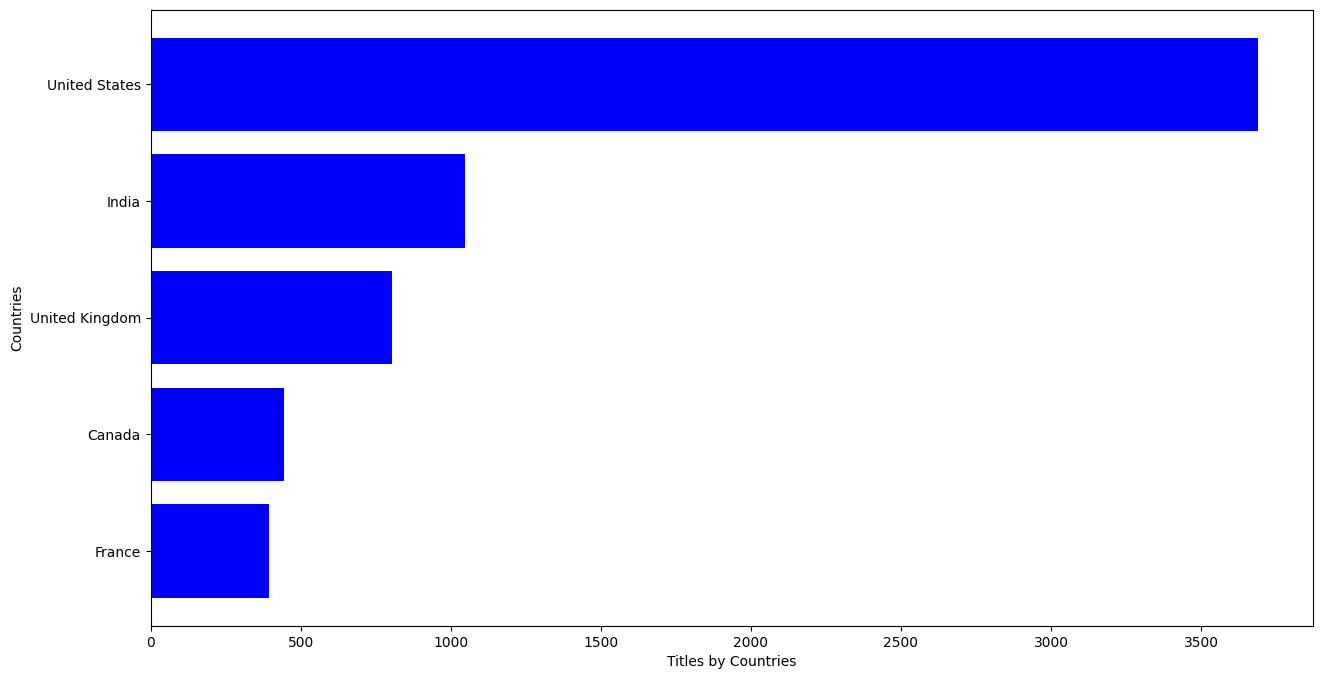

In [118]:
df_country=df_final1.groupby(['country_list']).agg({"title":"nunique"}).reset_index().sort_values(by=['title'],ascending=False)[:5]
plt.figure(figsize=(15,8))
plt.barh(df_country[::-1]['country_list'], df_country[::-1]['title'],color=['blue'])
plt.xlabel('Titles by Countries')
plt.ylabel('Countries')
plt.show()

US,India,UK,Canada and France are leading countries in Content Creation on Netflix

In [119]:
#number of distinct titles on the basis of rating
df_final1.groupby(['rating']).agg({"title":"nunique"})

,title
rating,
G,41
NC-17,3
NR,87
PG,287
PG-13,490
R,799
TV-14,2160
TV-G,220
TV-MA,3207


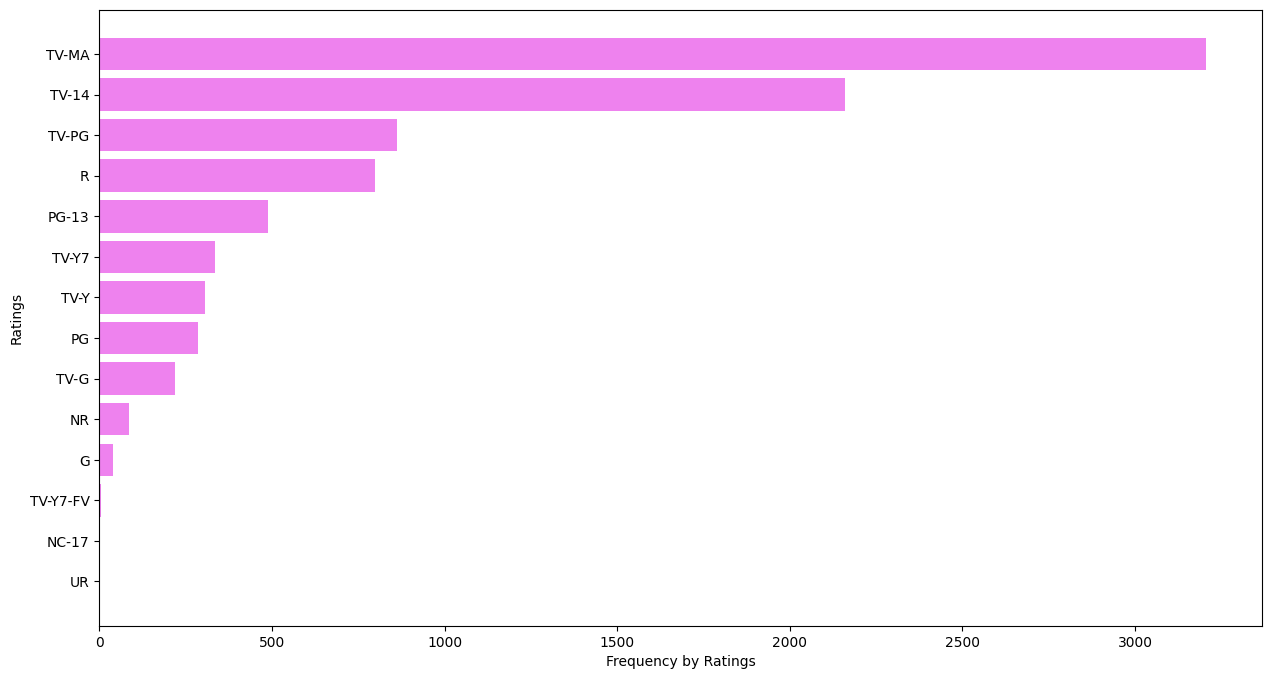

In [120]:
df_rating=df_final1.groupby(['rating']).agg({"title":"nunique"}).reset_index().sort_values(by=['title'],ascending=False)[:15]
plt.figure(figsize=(15,8))
plt.barh(df_rating[::-1]['rating'], df_rating[::-1]['title'],color=['violet'])
plt.xlabel('Frequency by Ratings')
plt.ylabel('Ratings')
plt.show()

Most of the highly rated content on Netflix is intended for Mature Audiences.

In [121]:
#number of distinct titles on the basis of duration
df_final1.groupby(['duration']).agg({"title":"nunique"})

,title
duration,
1 Season,1793
1-50,287
10 Seasons,7
101-120,1672
11 Seasons,2
12 Seasons,2
121-150,897
13 Seasons,3
15 Seasons,2


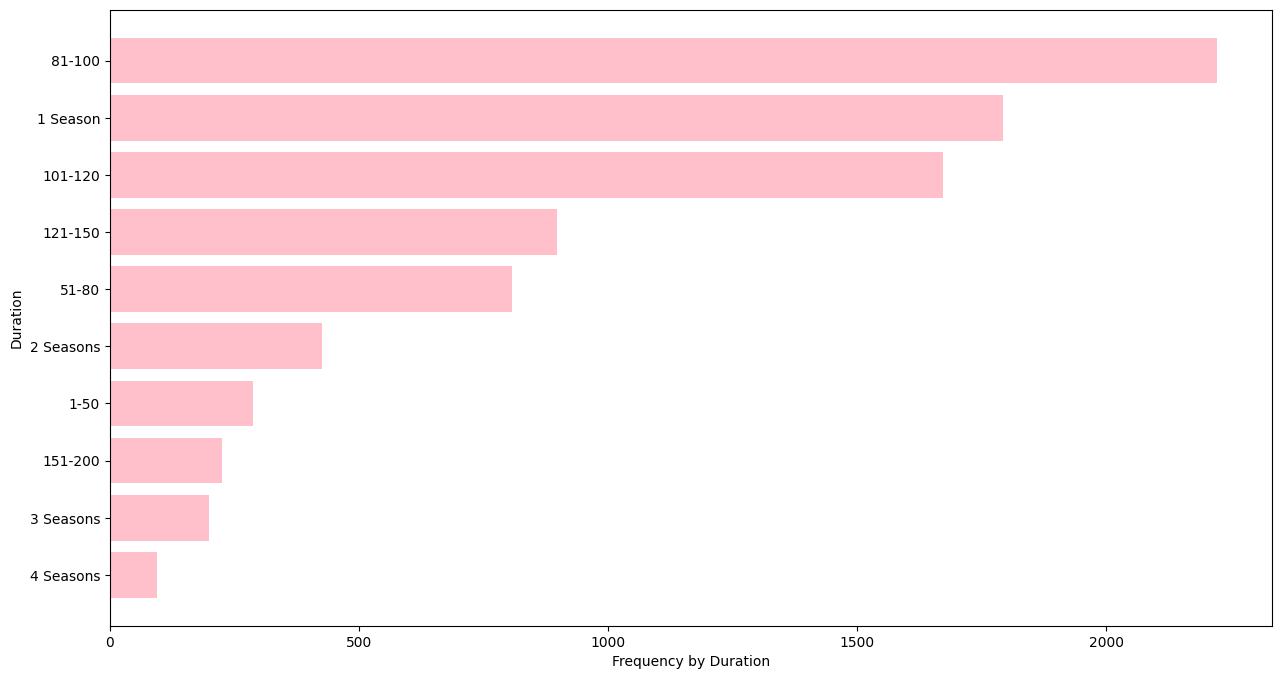

In [122]:
df_duration=df_final1.groupby(['duration']).agg({"title":"nunique"}).reset_index().sort_values(by=['title'],ascending=False)[:10]
plt.figure(figsize=(15,8))
plt.barh(df_duration[::-1]['duration'], df_duration[::-1]['title'],color=['pink'])
plt.xlabel('Frequency by Duration')
plt.ylabel('Duration')
plt.show()

The duration of Most Watched content in our whole data is 81-100 mins. Followed by TV shows with only 1 season.

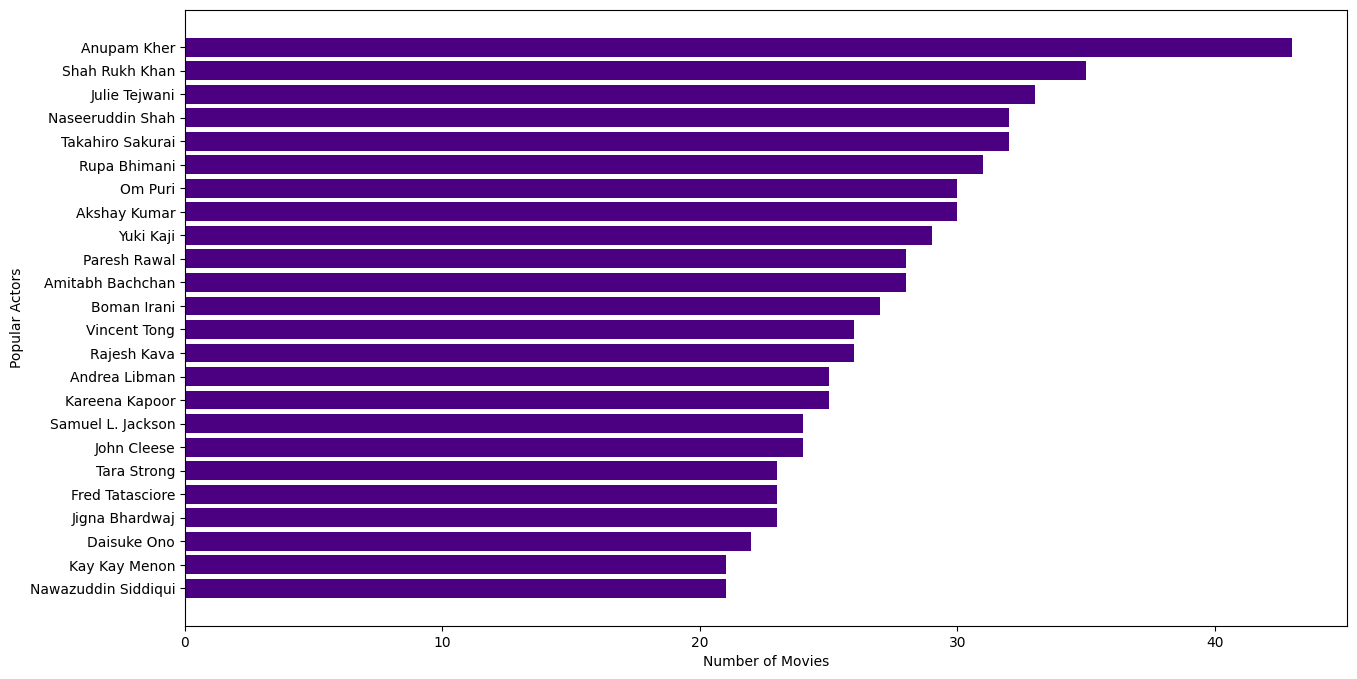

In [123]:
df_actors=df_final1.groupby(['actor']).agg({"title":"nunique"}).reset_index().sort_values(by=['title'],ascending=False)[:25]
df_actors=df_actors[df_actors['actor']!='Unknown Actor']
plt.figure(figsize=(15,8))
plt.barh(df_actors[::-1]['actor'], df_actors[::-1]['title'],color=['indigo'])
plt.xlabel('Number of Movies')
plt.ylabel('Popular Actors')
plt.show()

Anupam Kher,SRK,Julie Tejwani, Naseeruddin Shah and Takahiro Sakurai occupy the top stop in Most Watched content.

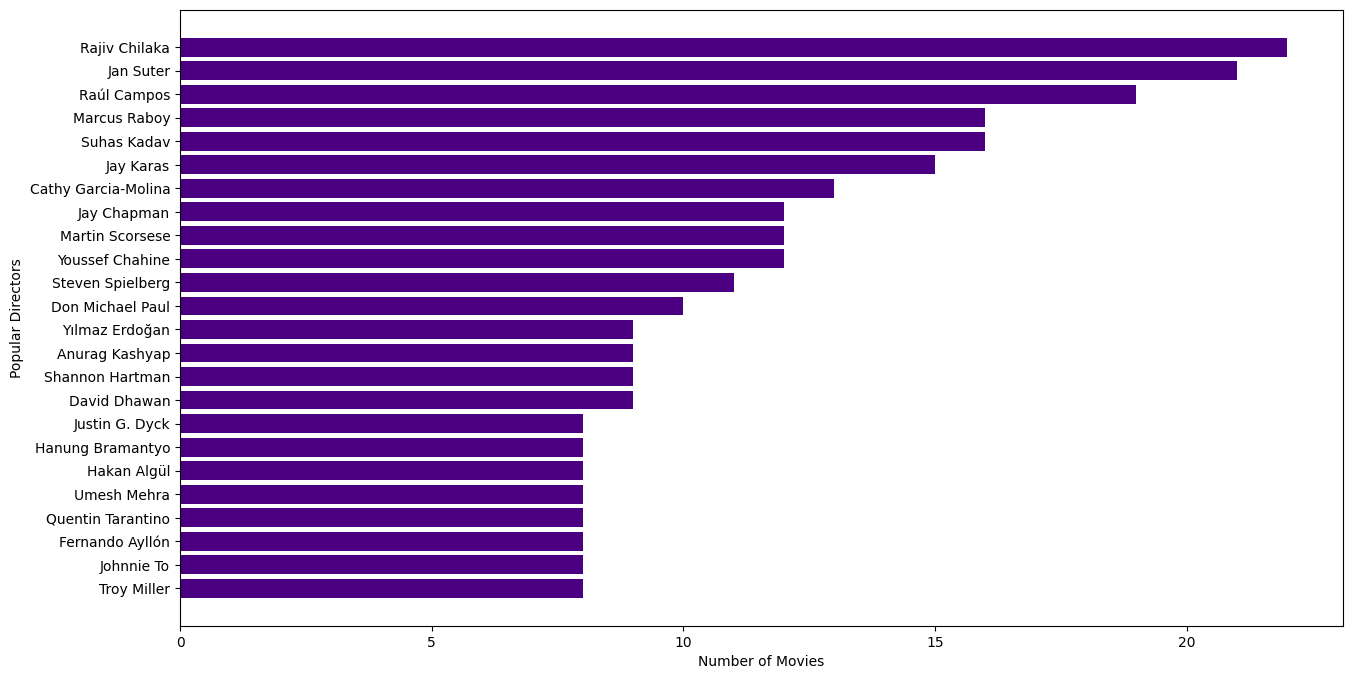

In [124]:
df_directors=df_final1.groupby(['director_list']).agg({"title":"nunique"}).reset_index().sort_values(by=['title'],ascending=False)[:25]
df_directors=df_directors[df_directors['director_list']!='Unknown Director']
plt.figure(figsize=(15,8))
plt.barh(df_directors[::-1]['director_list'], df_directors[::-1]['title'],color=['indigo'])
plt.xlabel('Number of Movies')
plt.ylabel('Popular Directors')
plt.show()

Rajiv Chilaka, Jan Suter and Raul Campos are the most popular directors across Netflix.

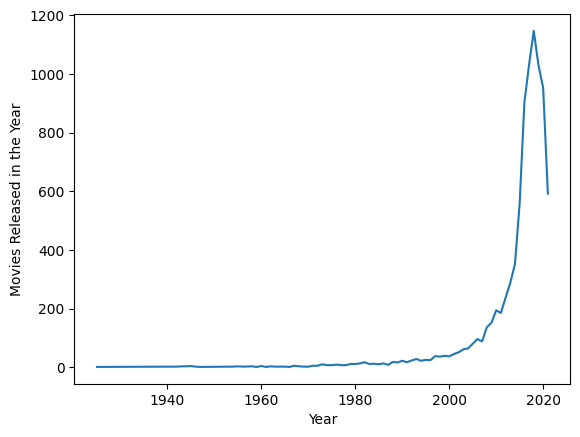

In [125]:
df_year=df_final1.groupby(['release_year']).agg({"title":"nunique"}).reset_index()
sns.lineplot(data=df_year, x='release_year', y='title')
plt.ylabel("Movies Released in the Year")
plt.xlabel("Year")
plt.show()

The Amount of Content across Netflix has increased from 2008 continuously till 2019. Then started decreasing from here(probably due to Covid)

**Recommendations**

1)The most popular Genres across the countries and in both TV Shows and Movies are Drama, Comedy and International TV Shows/Movies, so content aligning to that is recommended.

2) Audience of US and India consume the most content so Movies and TV Shows should be made more for them compared to other countries.

3)81-120 mins is the recommended length for movies.

4)Maximum content is watched by mature audience so they should be targeted first followed by kid friendly content.

5)More Movies or Series should be made using popular Actors and Directors.